In [1]:
from pathlib import Path

fasta_file = Path("CFTR_HUMAN.fasta")

print("File found:", fasta_file.exists())

File found: True


In [2]:
with open("CFTR_HUMAN.fasta", "r") as file:
    lines = file.readlines()

header = lines[0].strip()
sequence = "".join(line.strip() for line in lines[1:])

print("Protein:", header)
print("Sequence length:", len(sequence))
print("First 20 amino acids:", sequence[:20])

Protein: >sp|P13569|CFTR_HUMAN Cystic fibrosis transmembrane conductance regulator OS=Homo sapiens OX=9606 GN=CFTR PE=1 SV=3
Sequence length: 1480
First 20 amino acids: MQRSPLEKASVVSKLFFSWT


In [3]:
from collections import Counter

amino_acid_counts = Counter(sequence)

print(amino_acid_counts)

Counter({'L': 183, 'S': 123, 'I': 119, 'E': 93, 'K': 92, 'V': 90, 'F': 85, 'G': 84, 'A': 83, 'T': 83, 'R': 78, 'Q': 67, 'D': 58, 'N': 54, 'P': 45, 'Y': 40, 'M': 37, 'H': 25, 'W': 23, 'C': 18})


In [4]:
from collections import Counter

amino_acid_counts = Counter(sequence)

print(amino_acid_counts)

Counter({'L': 183, 'S': 123, 'I': 119, 'E': 93, 'K': 92, 'V': 90, 'F': 85, 'G': 84, 'A': 83, 'T': 83, 'R': 78, 'Q': 67, 'D': 58, 'N': 54, 'P': 45, 'Y': 40, 'M': 37, 'H': 25, 'W': 23, 'C': 18})


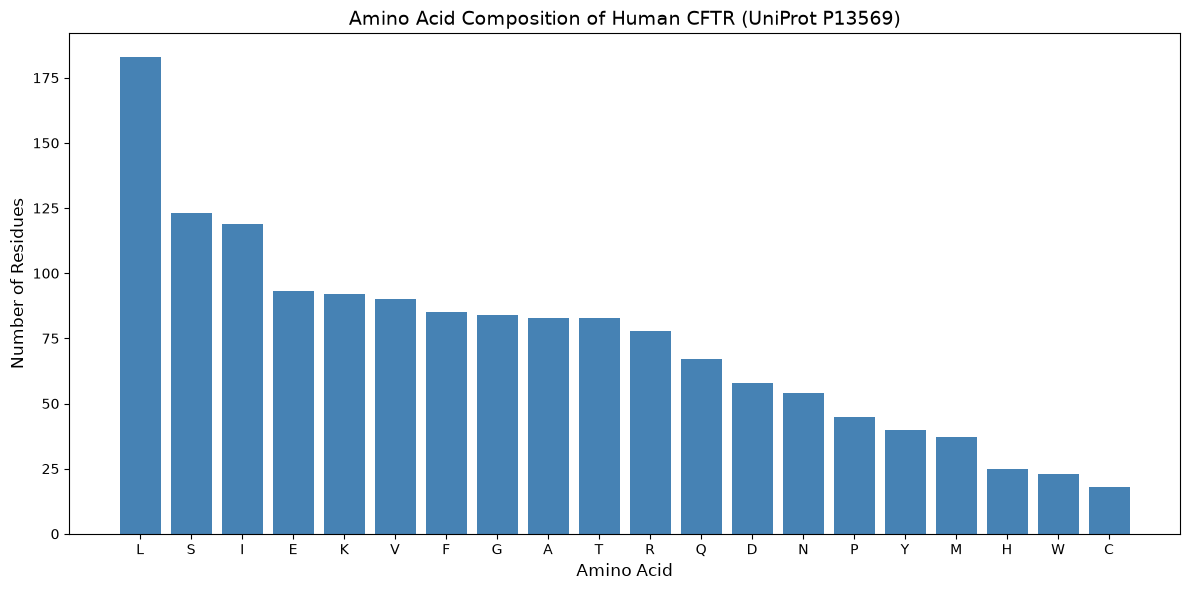

In [6]:
import matplotlib.pyplot as plt

# Sort amino acids by frequency
sorted_counts = amino_acid_counts.most_common()

amino_acids = [aa for aa, count in sorted_counts]
counts = [count for aa, count in sorted_counts]

# Create figure
plt.figure(figsize=(12, 6))

plt.bar(amino_acids, counts, color="steelblue")

plt.xlabel("Amino Acid", fontsize=12)
plt.ylabel("Number of Residues", fontsize=12)
plt.title("Amino Acid Composition of Human CFTR (UniProt P13569)", fontsize=14)

plt.tight_layout()

# Save a high-resolution figure for GitHub
plt.savefig("CFTR_Amino_Acid_Composition.png", dpi=300)

plt.show()

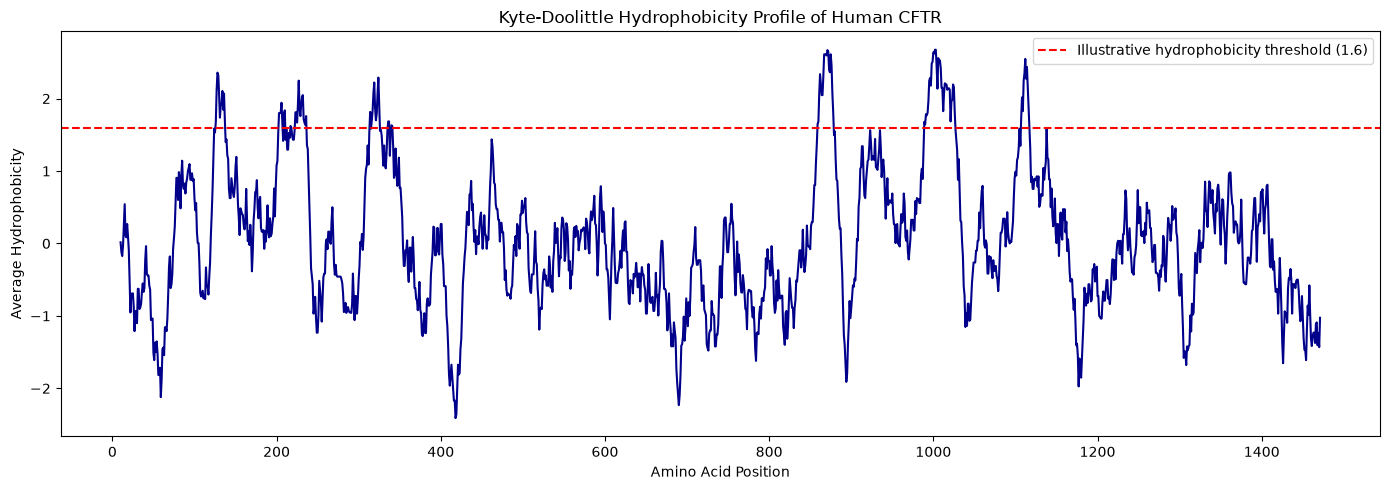

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Kyte-Doolittle hydrophobicity scale
hydrophobicity = {
    "A": 1.8, "R": -4.5, "N": -3.5, "D": -3.5,
    "C": 2.5, "Q": -3.5, "E": -3.5, "G": -0.4,
    "H": -3.2, "I": 4.5, "L": 3.8, "K": -3.9,
    "M": 1.9, "F": 2.8, "P": -1.6, "S": -0.8,
    "T": -0.7, "W": -0.9, "Y": -1.3, "V": 4.2
}

# Convert amino acid sequence to hydrophobicity values
values = np.array([hydrophobicity[aa] for aa in sequence])

# Calculate sliding-window average
window = 19
profile = np.convolve(
    values,
    np.ones(window) / window,
    mode="valid"
)

positions = np.arange(window // 2 + 1, len(sequence) - window // 2 + 1)

# Plot
plt.figure(figsize=(14, 5))
plt.plot(positions, profile, color="darkblue", linewidth=1.5)
plt.axhline(1.6, color="red", linestyle="--",
            label="Illustrative hydrophobicity threshold (1.6)")

plt.xlabel("Amino Acid Position")
plt.ylabel("Average Hydrophobicity")
plt.title("Kyte-Doolittle Hydrophobicity Profile of Human CFTR")
plt.legend()
plt.tight_layout()

plt.savefig("CFTR_Hydrophobicity_Profile.png", dpi=300)
plt.show()

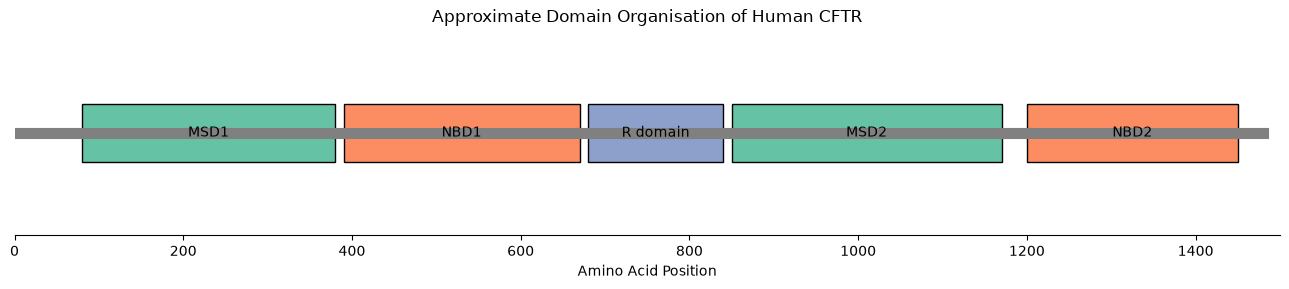

In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Approximate CFTR domain regions
domains = [
    ("MSD1", 80, 380, "#66c2a5"),
    ("NBD1", 390, 670, "#fc8d62"),
    ("R domain", 680, 840, "#8da0cb"),
    ("MSD2", 850, 1170, "#66c2a5"),
    ("NBD2", 1200, 1450, "#fc8d62")
]

fig, ax = plt.subplots(figsize=(13, 3))

# Full-length CFTR protein
ax.plot([1, 1480], [0, 0], color="grey", linewidth=8)

for name, start, end, colour in domains:
    ax.add_patch(
        Rectangle(
            (start, -0.2),
            end - start,
            0.4,
            facecolor=colour,
            edgecolor="black"
        )
    )
    ax.text((start + end) / 2, 0, name,
            ha="center", va="center", fontsize=10)

ax.set_xlim(0, 1500)
ax.set_ylim(-0.7, 0.7)
ax.set_xlabel("Amino Acid Position")
ax.set_yticks([])
ax.set_title("Approximate Domain Organisation of Human CFTR")

for spine in ["left", "right", "top"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig("CFTR_Protein_Domains.png", dpi=300)
plt.show()